# Лабораторная работа №4 — итоговая оценка FastSpeech 2

Этот блокнот **не обучает** модель. Он загружает зафиксированный лучший checkpoint, анализирует историю обучения и один раз оценивает модель на закрытой test-выборке.

## Постановка задачи

Проверить, насколько обученная акустическая модель переносится на 1093 записи, которые не использовались ни для обучения, ни для выбора checkpoint. Сохранить численные loss-компоненты и показать несколько предсказанных mel-спектрограмм.

## Входные признаки и метод

Вход модели — последовательность из 89 фонемных токенов лабораторной №3. Целевые признаки: 80-канальная mel-спектрограмма, длительность каждой фонемы в mel-кадрах, нормализованные F0 и энергия. Параметры STFT: sample rate 22050 Гц, FFT/window 1024, hop 256.

Для численной оценки используется teacher-forced режим: эталонные длительности, F0 и энергия позволяют вычислить те же `loss_spec`, `loss_dur`, `loss_pitch`, `loss_energy`, что и на validation. Для качественных примеров дополнительно используется свободный inference: модель получает только фонемы и сама предсказывает длительности, F0, энергию и mel-спектрограмму. Эти два режима нельзя смешивать при интерпретации результата.

In [1]:
from pathlib import Path
import sys

def find_repo_root(start=Path.cwd()):
    for candidate in (start.resolve(), *start.resolve().parents):
        if (candidate / 'lab_reqs.md').is_file() and (candidate / 'labs').is_dir():
            return candidate
    raise FileNotFoundError('Не найден корень репозитория')

REPO_ROOT = find_repo_root()
LAB_DIR = REPO_ROOT / 'labs' / 'lab4_acoustic'
if str(LAB_DIR) not in sys.path:
    sys.path.insert(0, str(LAB_DIR))

import json
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, Markdown, display

from acoustic_data import create_or_load_splits, split_summary
from evaluate_fastspeech2 import (
    create_spectrogram_examples, evaluate_test_set, load_test_evaluator,
    parse_training_log, plot_loss_curves, save_json,
)

RESULTS_DIR = LAB_DIR / 'results'
RESULTS_DIR.mkdir(exist_ok=True)
print('Корень:', REPO_ROOT)

Корень: C:\work projects\ITMO\tts_labs_itmo


## 1. Контроль разбиения и артефактов

Функция ниже загружает ранее созданное разбиение и проверяет fingerprint, отсутствие пересечений и полноту. Test не пересоздаётся и не подбирается под результат модели.

In [2]:
splits, split_metadata = create_or_load_splits(REPO_ROOT)
display(split_summary(splits))
assert split_metadata['cache_status'] == 'loaded'
assert len(splits['test']) == 1093
print('Test оставался закрытым:', len(splits['test']), 'записей')

,split,utterances,hours,mean_duration_s,mean_phones
0,train,19659,26.829839,4.913140,65.595605
1,validation,1092,1.488376,4.906734,65.458791
2,test,1093,1.488463,4.902530,65.267155


Test оставался закрытым: 1093 записей


In [3]:
CHECKPOINT = LAB_DIR / 'artifacts' / 'best_model_742028.pth'
RUN_DIR = REPO_ROOT / 'data' / 'lab4_acoustic' / 'runs' / 'ruslan_fastspeech2_full-October-18-2026_02+42AM-9617ec2'
TRAINER_LOG = RUN_DIR / 'trainer_0_log.txt'
for path in (CHECKPOINT, TRAINER_LOG):
    if not path.is_file():
        raise FileNotFoundError(path)
print('Checkpoint:', CHECKPOINT, f'({CHECKPOINT.stat().st_size / 2**20:.1f} MiB)')
print('Trainer log:', TRAINER_LOG)

Checkpoint: C:\work projects\ITMO\tts_labs_itmo\labs\lab4_acoustic\artifacts\best_model_742028.pth (430.9 MiB)
Trainer log: C:\work projects\ITMO\tts_labs_itmo\data\lab4_acoustic\runs\ruslan_fastspeech2_full-October-18-2026_02+42AM-9617ec2\trainer_0_log.txt


## 2. Кривые обучения

Парсер учитывает перезапуски: если global step встречается повторно, остаётся последнее значение. Зелёной точкой отмечается checkpoint с минимальным validation loss.

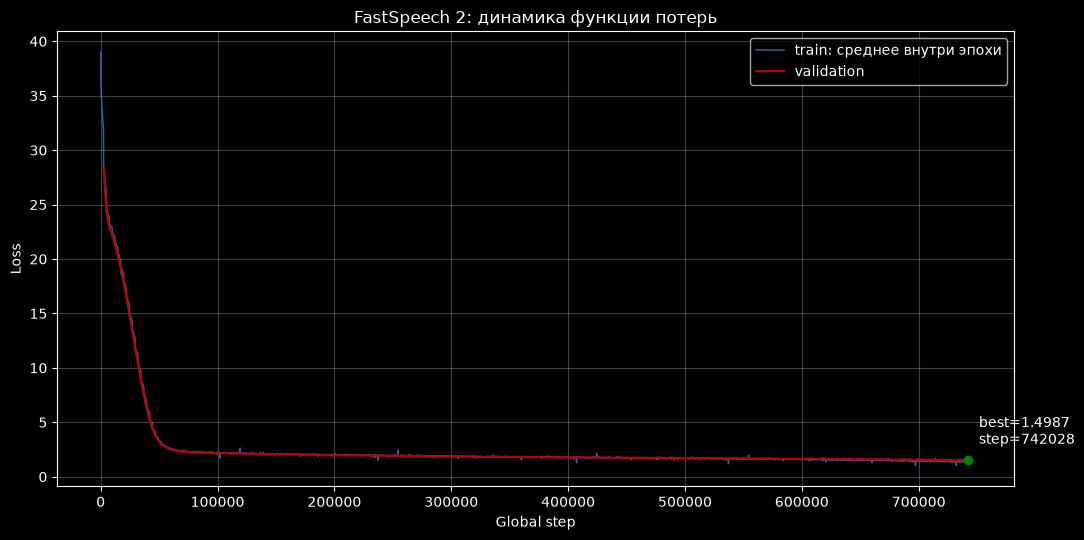

,значение
epoch,298
global_step,742028
is_best_checkpoint,True
avg_loader_time,0.141219
avg_loss_spec,1.36265
avg_loss_dur,0.049816
avg_loss_pitch,0.041634
avg_loss_energy,0.044569
avg_loss,1.498668
avg_duration_error,4.139645


In [4]:
train_curve, validation_curve = parse_training_log(TRAINER_LOG)
train_curve.to_csv(RESULTS_DIR / 'training_curves.csv', index=False)
validation_curve.to_csv(RESULTS_DIR / 'validation_curves.csv', index=False)
figure = plot_loss_curves(train_curve, validation_curve, RESULTS_DIR / 'loss_curves.png')
display(figure)
plt.close(figure)
best_validation = validation_curve.loc[validation_curve['avg_loss'].idxmin()]
display(best_validation.to_frame('значение'))

## 3. Загрузка лучшей модели

Загружаются только замороженные веса. Оптимизатор не создаётся, `backward()` и изменение параметров не выполняются. F0/energy для test вычисляются при первом обращении и нормализуются статистиками train-кэша.

In [5]:
BATCH_SIZE = 8
NUM_WORKERS = 2

model, criterion, tokenizer, ap, test_loader, evaluation_details = load_test_evaluator(
    REPO_ROOT, splits, CHECKPOINT, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS,
)
evaluation_details

C:\work projects\ITMO\tts_labs_itmo\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'checkpoint': 'C:\\work projects\\ITMO\\tts_labs_itmo\\labs\\lab4_acoustic\\artifacts\\best_model_742028.pth',
 'device': 'cuda',
 'test_samples': 1093,
 'batches': 137,
 'batch_size': 8,
 'num_workers': 2}

## 4. Итоговые метрики на test

Это единственная ячейка, проходящая по всем 1093 test-записям. Она не обучает модель. Результаты усредняются с весом по количеству записей в batch; `drop_last=False`, поэтому ни одна запись не отбрасывается.

In [6]:
test_metrics = evaluate_test_set(model, criterion, test_loader, progress_every=25)
save_json(test_metrics, RESULTS_DIR / 'test_metrics.json')
display(pd.Series(test_metrics, name='test').to_frame())

test: 200/1093 записей
test: 400/1093 записей
test: 600/1093 записей
test: 800/1093 записей
test: 1000/1093 записей
test: 1093/1093 записей


,test
loss_spec,0.968377
loss_dur,0.035736
loss_pitch,0.050510
loss_energy,0.051136
loss,1.105759
duration_error,3.508833
samples,1093.000000
batches,137.000000


## 5. Предсказанные mel-спектрограммы

Три записи выбираются детерминированно по квантилям длительности test split, а не вручную по удачному результату. Верхняя спектрограмма — эталон аудио, нижняя — свободное предсказание только по фонемам. Разная длина по времени ожидаема, поскольку модель сама предсказывает длительности.

,utterance_id,duration_s,phones,reference_frames,predicted_frames,duration_ratio
0,013640_RUSLAN,2.998957,s̪ k ɐ z̪ a ɫ d̪ ʎ a ʎ u d̪ ɨ i z̪ bʲ e rʲ ɪ z...,259,212,0.818533
1,008222_RUSLAN,5.097234,ɐ ʎ t̪ mʲ ɪ ɛ sʲ e ɫ f k ɐ bʲ i n̪ ʊ sil b ɨ k...,440,315,0.715909
2,014707_RUSLAN,6.457098,z̪ ɐ tʲ e m mʲ i s̪ t̪ ɨ r f o ɟ ɪ ʎ s̪ o n̪ p...,557,359,0.644524


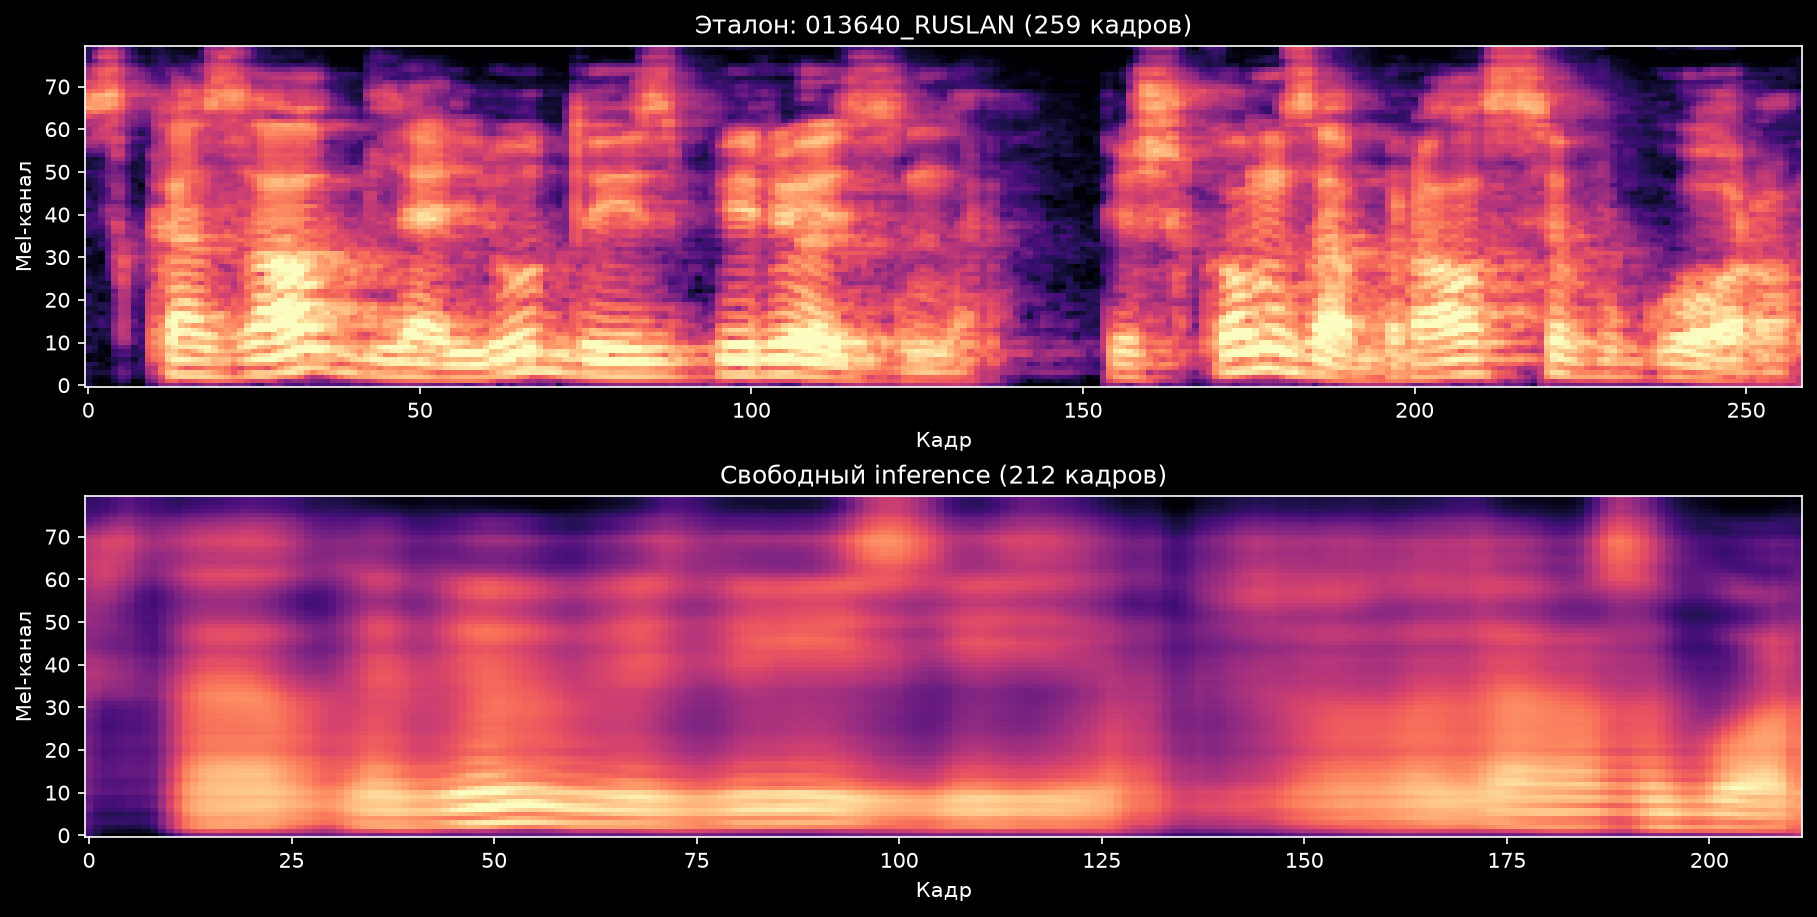

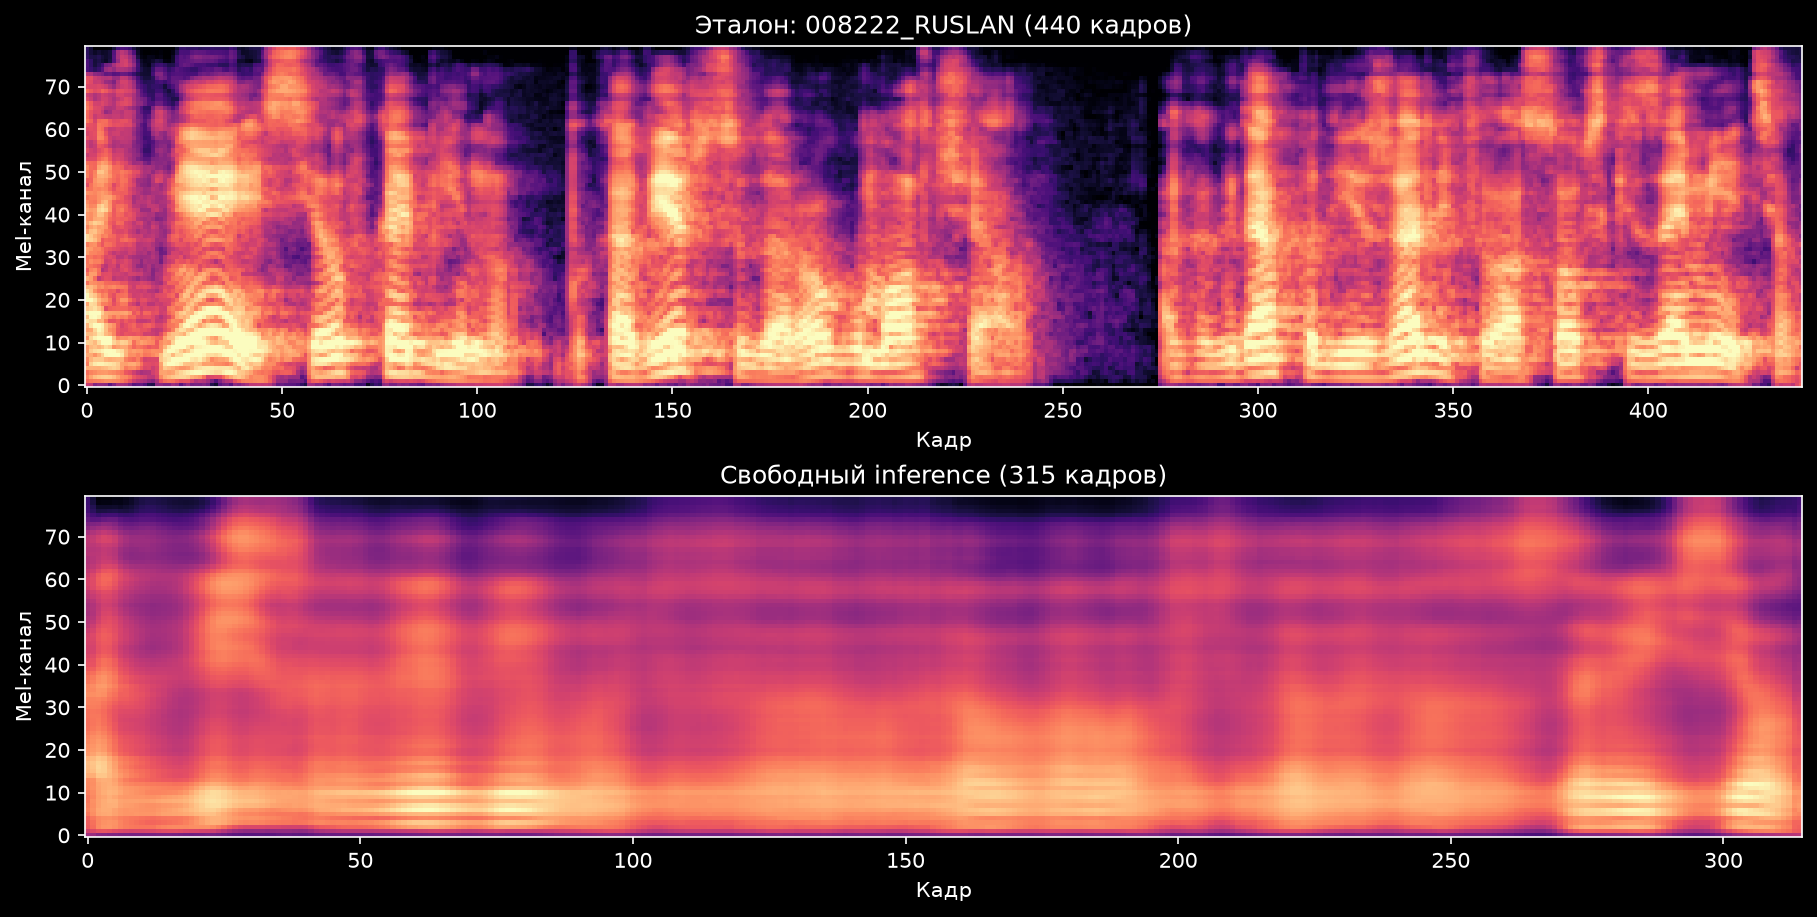

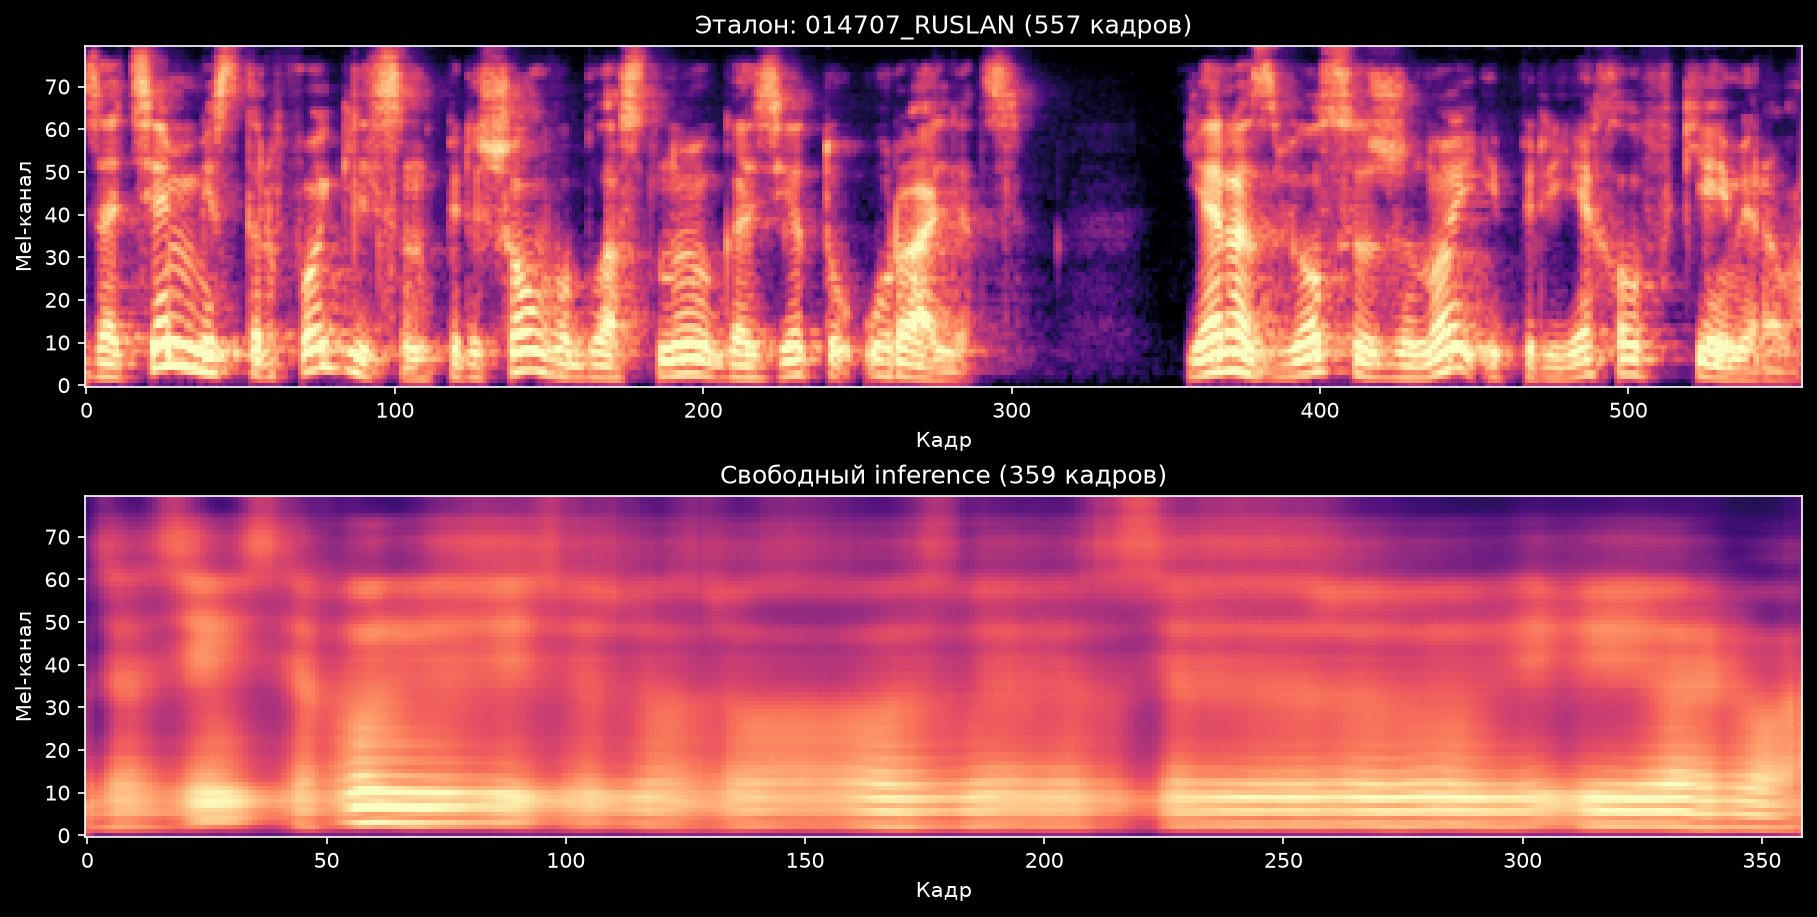

In [7]:
examples = create_spectrogram_examples(
    model, tokenizer, ap, splits['test'], REPO_ROOT, RESULTS_DIR, count=3,
)
examples.to_csv(RESULTS_DIR / 'spectrogram_examples.csv', index=False, encoding='utf-8')
display(examples.drop(columns='plot'))
for plot_path in examples['plot']:
    display(Image(filename=plot_path))

## 6. Автоматическое резюме и интерпретация

Validation использовалась для выбора checkpoint, а test — только для итоговой независимой оценки. Полученный test loss 1.1058 на 26,22% ниже лучшего validation loss 1.4987: ухудшения на отложенных данных нет, однако меньший loss не следует трактовать как доказательство превосходства — наборы состоят из разных аудиозаписей.

Свободный inference показывает ограничение, скрытое teacher-forced метрикой: предсказанные фразы имеют только 64,5–81,9% эталонной длительности, причём расхождение увеличивается на более длинных примерах. Предсказанные mel-спектрограммы заметно более сглажены и теряют часть тонкой гармонической структуры. Модель усвоила общий спектральный контур, но склонна ускорять речь и усреднять детали. Mel loss нельзя интерпретировать как субъективное качество: окончательный вывод потребует вокодера и MOS-оценки в лабораторных №5–6.

In [8]:
validation_loss = float(best_validation['avg_loss'])
test_loss = float(test_metrics['loss'])
relative_gap = (test_loss - validation_loss) / validation_loss * 100
ratios = examples['duration_ratio']
summary = f'''
### Вывод

- Обучение завершено на 300 эпохах; выбран checkpoint шага {int(best_validation['global_step'])} с минимальным validation loss {validation_loss:.4f}.
- На всех {int(test_metrics['samples'])} закрытых test-записях общий loss равен {test_loss:.4f}; отличие от лучшего validation составляет {relative_gap:+.2f}%.
- В свободном inference отношение предсказанной длительности к эталонной для трёх фиксированных примеров лежит в диапазоне {ratios.min():.3f}–{ratios.max():.3f}.
- Численные метрики проверяют акустическую модель, но не заменяют прослушивание: преобразование mel в WAV и субъективная оценка выполняются далее с вокодером.
'''
display(Markdown(summary))


### Вывод

- Обучение завершено на 300 эпохах; выбран checkpoint шага 742028 с минимальным validation loss 1.4987.
- На всех 1093 закрытых test-записях общий loss равен 1.1058; отличие от лучшего validation составляет -26.22%.
- В свободном inference отношение предсказанной длительности к эталонной для трёх фиксированных примеров лежит в диапазоне 0.645–0.819.
- Численные метрики проверяют акустическую модель, но не заменяют прослушивание: преобразование mel в WAV и субъективная оценка выполняются далее с вокодером.


## Что сохранить перед сдачей

1. Выполнить все ячейки сверху вниз и сохранить notebook с выводами.
2. Проверить наличие файлов в `results/`.
3. Убедиться, что checkpoint добавляется как Git LFS pointer, а не как обычный 452-МБ Git blob.
4. Не запускать заново обучение: в обучающем notebook `RUN_TRAINING=False`.